# GDP growth: autoregressive dynamics and forecasting

Estimate and compare the persistence of quarterly real GDP growth in the
**United States and Germany**. Choose an AR order, interpret the coefficients
and produce a next-quarter forecast.

The main sample is **1996Q2-2019Q4 (95 quarters)**, before the pandemic.
A short final comparison extends estimation through 2025Q4. All data are
included locally; no download or API key is needed.

Data Sources:

- BEA [US real GDP, GDPC1](https://fred.stlouisfed.org/series/GDPC1), through FRED.
- [Eurostat quarterly national accounts, `namq_10_gdp`](https://ec.europa.eu/eurostat/databrowser/view/namq_10_gdp/default/table?lang=en):
  German real GDP, seasonally and calendar adjusted.

The data are revised values retrieved on 13 October 2026. The forecast from
2019Q4 is a historical teaching exercise using this vintage.

## Environment setup

**Colab:** upload the complete `Notebooks` folder to **My Drive**, keeping the
subfolders and CSV files. Run the cell below and authorize Drive access.
**Local Jupyter:** keep the same folder structure and run the cell below.
If the folder is elsewhere, set `NOTEBOOKS_ROOT` to its full path.


In [1]:
from pathlib import Path

# Usually leave this as None. If needed, enter the path to the folder
# containing all tutorial subfolders (Google Drive or the Colab runtime).
NOTEBOOKS_ROOT = None
TUTORIAL = "Time_Series"

try:
    from google.colab import drive
except ImportError:
    IN_COLAB = False
else:
    IN_COLAB = True

if IN_COLAB:
    notebooks_root = Path(NOTEBOOKS_ROOT or "/content/drive/MyDrive/Notebooks")
    if notebooks_root.is_relative_to("/content/drive"):
        drive.mount("/content/drive")
else:
    if NOTEBOOKS_ROOT is not None:
        notebooks_root = Path(NOTEBOOKS_ROOT).expanduser().resolve()
    else:
        # Work from the tutorial folder, Notebooks, or the course folder.
        here = Path.cwd().resolve()
        candidates = [here, *here.parents]
        candidates += [parent / "Notebooks" for parent in [here, *here.parents]]
        notebooks_root = next(
            (root for root in candidates if (root / TUTORIAL).is_dir()), here
        )

DATA_DIR = notebooks_root / TUTORIAL
if not DATA_DIR.is_dir():
    raise FileNotFoundError(
        f"Tutorial folder not found: {DATA_DIR}. "
        "Upload the complete Notebooks folder to My Drive, or set "
        "NOTEBOOKS_ROOT to the folder containing the tutorial subfolders."
    )
print(f"Data folder found: {DATA_DIR.name}")

Data folder found: Time_Series


## Libraries

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from statsmodels.tsa.ar_model import AutoReg
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.stats.diagnostic import acorr_ljungbox
from IPython.display import display

## Data

Calculate quarterly log growth from positive real GDP levels:

$$g_t=100[\log(Y_t)-\log(Y_{t-1})].$$

Growth is approximately a percentage change **from one quarter to the next**,
without annualisation. The US level is reported at an annual rate, whose
constant scaling cancels in the ratio. Rebase the two level series to 100 for
visual comparison; their original currencies and units differ.

1996Q1 supplies the first growth base. Use all subsequent quarters through
2019Q4 for the main analysis. Later observations supply the held-out forecast
outcome and the final sample comparison.
Differencing removes the level trend but does not by itself establish stationarity.

Main growth sample: 1996Q2 to 2019Q4, 95 quarters per country


,United States,Germany
quarter,,
1996Q2,1.654,1.408
1996Q3,0.893,0.349
1996Q4,1.033,0.933
1997Q1,0.643,-0.522
1997Q2,1.652,1.154


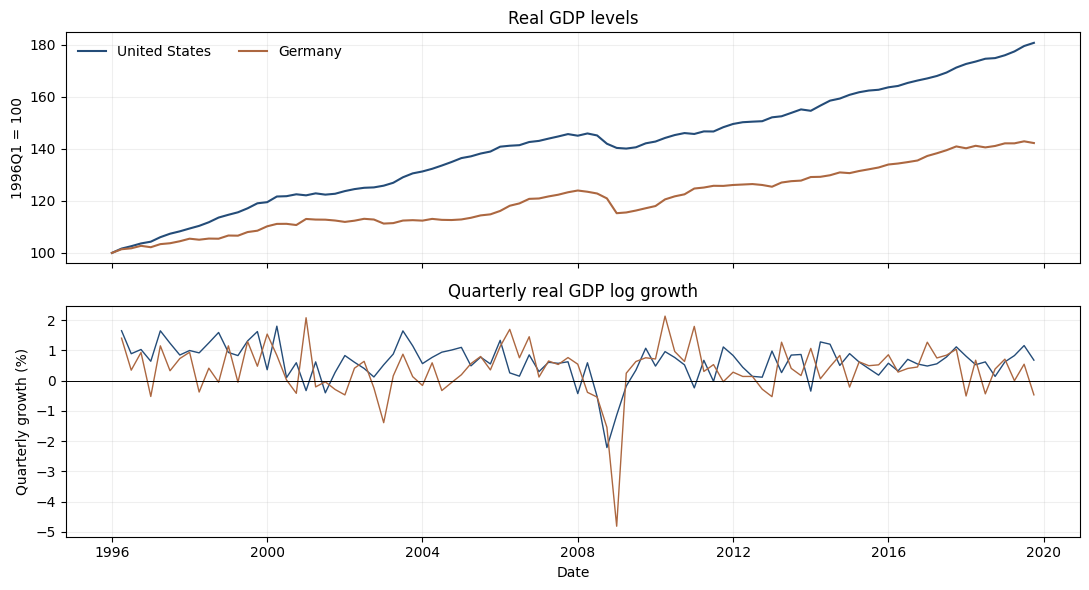

In [3]:
levels = pd.read_csv(DATA_DIR / "quarterly_real_gdp.csv", index_col="quarter")
levels.index = pd.PeriodIndex(levels.index, freq="Q")
countries = ["United States", "Germany"]
if list(levels.columns) != countries or levels.isna().any().any() or not levels.gt(0).all().all():
    raise ValueError("Inspect the GDP columns, missing observations and positive levels.")
if not levels.index.equals(pd.period_range(levels.index[0], levels.index[-1], freq="Q")):
    raise ValueError("Missing, duplicate or unordered quarters: inspect the CSV.")
all_growth = (100 * np.log(levels).diff()).iloc[1:]
growth = all_growth.loc[:"2019Q4"].copy()
main_levels = levels.loc[:"2019Q4"]
indexed_gdp = 100 * main_levels / main_levels.iloc[0]
colors = {"United States": "#244c78", "Germany": "#ac6740"}
print(f"Main growth sample: {growth.index[0]} to {growth.index[-1]}, {len(growth)} quarters per country")
display(growth.head().round(3))

fig, axes = plt.subplots(2, 1, figsize=(11, 6), sharex=True)
for country in countries:
    axes[0].plot(indexed_gdp.index.to_timestamp(), indexed_gdp[country], color=colors[country], label=country)
    axes[1].plot(growth.index.to_timestamp(), growth[country], color=colors[country], linewidth=1)
axes[0].set(title="Real GDP levels", ylabel="1996Q1 = 100")
axes[0].legend(frameon=False, ncol=2)
axes[1].set(title="Quarterly real GDP log growth", ylabel="Quarterly growth (%)", xlabel="Date")
axes[1].axhline(0, color="black", linewidth=0.7)
for ax in axes:
    ax.grid(alpha=0.2)
fig.tight_layout()
plt.show()

## ACF and PACF

The ACF measures correlation between growth and its lagged values. The PACF
measures that association after controlling for intermediate lags. For a
stationary population AR($p$), the PACF cuts off after lag $p$, while the ACF
usually decays. Sample plots are noisy, so use them as guides to lag selection.
Each lag is one quarter; the shaded 95% bands are approximate and pointwise.

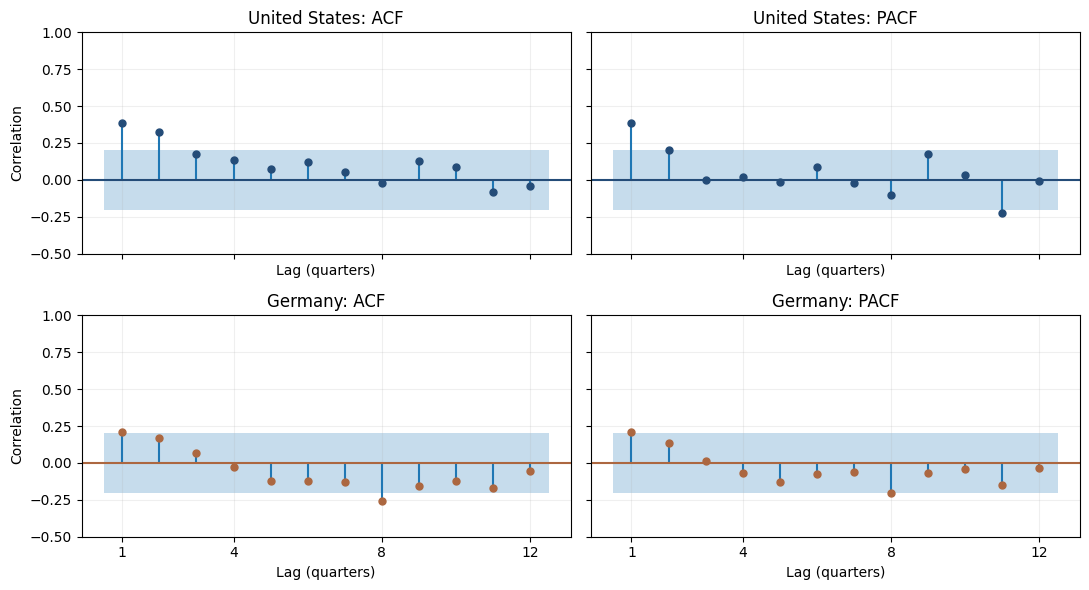

In [4]:
fig, axes = plt.subplots(2, 2, figsize=(11, 6), sharex=True, sharey=True)
for row, country in enumerate(countries):
    plot_acf(growth[country], lags=12, zero=False, bartlett_confint=False,
             ax=axes[row, 0], color=colors[country])
    plot_pacf(growth[country], lags=12, zero=False, method="ywm",
              ax=axes[row, 1], color=colors[country])
    for col, name in enumerate(["ACF", "PACF"]):
        axes[row, col].set(title=f"{country}: {name}", xlabel="Lag (quarters)", ylim=(-0.5, 1))
        axes[row, col].set_xticks([1, 4, 8, 12])
        axes[row, col].grid(alpha=0.2)
    axes[row, 0].set_ylabel("Correlation")
fig.tight_layout()
plt.show()

## The AR model and lag selection

Estimate an autoregression with an intercept:

$$g_t=c+\phi_1g_{t-1}+\cdots+\phi_pg_{t-p}+u_t.$$

Compare orders $p=0,\ldots,8$ by conditional OLS. AR(0) is an intercept-only
benchmark. Hold back the first eight growth observations for **every model**,
so all candidates use the same **87 quarters, 1998Q2-2019Q4**.

$$\mathrm{AIC}=-2\ell+2K,\qquad \mathrm{BIC}=-2\ell+K\log n.$$

Smaller values are preferred. $K=p+2$ counts the intercept, lag coefficients
and innovation variance; BIC penalises extra parameters more strongly than AIC.
Use BIC to choose the main model and report AIC for comparison.

In [5]:
MAX_ORDER = 8

def fit_candidates(y):
    models = {p: AutoReg(y, lags=p, trend="c", hold_back=MAX_ORDER).fit()
              for p in range(MAX_ORDER + 1)}
    table = pd.DataFrame({p: {"AIC": result.aic, "BIC": result.bic}
                          for p, result in models.items()}).T
    table.index.name = "p"
    return models, table, int(table["BIC"].idxmin())

fitted, criteria, selected_order = {}, {}, {}
for country in countries:
    models, table, p = fit_candidates(growth[country])
    fitted[country], criteria[country], selected_order[country] = models[p], table, p
display(pd.concat(criteria, axis=1).round(2))

United States         Germany        
            AIC     BIC     AIC     BIC
p                                      
0        158.56  163.49  224.73  229.67
1        147.49  154.89  221.78  229.18
2        146.22  156.09  222.77  232.64
3        148.22  160.55  224.71  237.04
4        150.21  165.00  226.09  240.88
5        152.19  169.45  226.54  243.80
6        153.09  172.81  228.01  247.74
7        155.00  177.19  229.61  251.80
8        156.06  180.72  227.85  252.51

## Estimates and interpretation

**BIC selects AR(1) for both countries**; AIC selects AR(2) for the USA and
AR(1) for Germany. The selected equation is $g_t=c+\phi g_{t-1}+u_t$.
$c$ is in percent per quarter and $\phi$ is dimensionless.

The intercept is fitted growth when last quarter's growth equals zero.
For $|\phi|<1$, the long-run mean is $\mu=c/(1-\phi)$.
The table reports coefficients, conventional standard errors, zero-coefficient
p-values and 95% confidence intervals. This inference assumes a suitable
innovation process and does not account for selecting the lag order.

The residual Ljung-Box test assesses zero residual autocorrelation at lags
1-12, using an approximate $\chi^2_{12-p}$ reference. A large p-value does not
validate all model assumptions; changing variance can affect the usual reference.

In [6]:
coefficient_rows, model_rows = [], []
for country, result in fitted.items():
    ci = np.asarray(result.conf_int(alpha=0.05))
    for j, (term, estimate) in enumerate(result.params.items()):
        coefficient_rows.append({"Country": country, "Term": "Intercept" if j == 0 else "Lag 1",
                                 "Estimate": estimate, "SE": result.bse.iloc[j],
                                 "p-value": result.pvalues.iloc[j],
                                 "95% lower": ci[j, 0], "95% upper": ci[j, 1]})
    phi = result.params.iloc[1]
    test = acorr_ljungbox(result.resid, lags=[12], model_df=selected_order[country], return_df=True).iloc[0]
    model_rows.append({"Country": country, "BIC order": selected_order[country],
                       "AIC order": int(criteria[country]["AIC"].idxmin()), "n": int(result.nobs),
                       "Long-run mean (%)": result.params.iloc[0] / (1 - phi),
                       "Residual LB p-value": test["lb_pvalue"]})
coefficients = pd.DataFrame(coefficient_rows).set_index(["Country", "Term"])
model_summary = pd.DataFrame(model_rows).set_index("Country")
display(coefficients.round(4))
display(model_summary.round(4))

Estimate      SE  p-value  95% lower  95% upper
Country       Term                                                      
United States Intercept    0.3607  0.0821   0.0000     0.1998     0.5216
              Lag 1        0.3724  0.0992   0.0002     0.1780     0.5668
Germany       Intercept    0.2586  0.0972   0.0078     0.0681     0.4492
              Lag 1        0.2358  0.1045   0.0240     0.0310     0.4405

,BIC order,AIC order,n,Long-run mean (%),Residual LB p-value
Country,,,,,
United States,1,2,87,0.5748,0.5962
Germany,1,1,87,0.3384,0.2697


## Persistence of growth innovations

The AR(1) coefficients are approximately **0.37 for the USA** and **0.24 for
Germany**. Under the fitted model, a one-percentage-point innovation to growth
has an effect $\psi_h=\phi^h$ after $h$ quarters. Both estimates imply positive
propagation that decays toward zero, with slower decay in the USA.

These are reduced-form growth innovations, not identified policy shocks.
Growth returning to its mean does not imply that the GDP level returns to its
previous path. Positive AR(1) persistence describes smooth decay; it does not
provide an oscillatory business-cycle period.

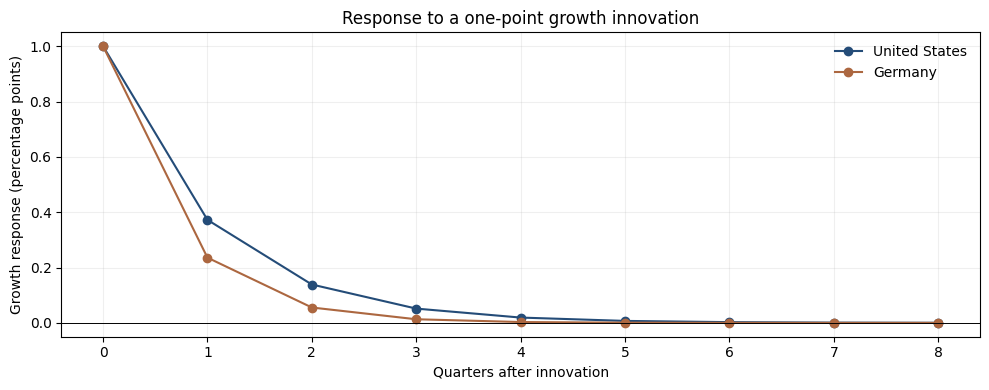

In [7]:
horizons = np.arange(9)
fig, ax = plt.subplots(figsize=(10, 4))
for country, result in fitted.items():
    response = result.params.iloc[1] ** horizons
    ax.plot(horizons, response, marker="o", color=colors[country], label=country)
ax.axhline(0, color="black", linewidth=0.7)
ax.set(title="Response to a one-point growth innovation", xlabel="Quarters after innovation",
       ylabel="Growth response (percentage points)")
ax.set_xticks(horizons)
ax.legend(frameon=False)
ax.grid(alpha=0.2)
fig.tight_layout()
plt.show()

## Next-quarter forecasting

From the origin **2019Q4**, forecast **2020Q1** using only the main sample:

$$\widehat g_{T+1|T}=\widehat c+\widehat\phi g_T.$$

Compare the forecast with the observed 2020Q1 value, which has not entered
order selection or estimation. The approximate 95% prediction interval is
for future growth, conditional on the fitted model. It omits parameter and
order uncertainty and assumes the fitted innovation variance remains relevant.
The forecast misses the pandemic-era contraction; this illustrates the limits
of extrapolating a model into an exceptional event. This is one historical
forecast per country using revised data, not a broad forecast-performance test.

In [8]:
next_quarter = growth.index[-1] + 1
forecast_rows = []
for country, result in fitted.items():
    prediction = result.get_prediction(start=len(growth), end=len(growth))
    interval = np.asarray(prediction.conf_int(alpha=0.05))[0]
    forecast = float(np.asarray(prediction.predicted_mean)[0])
    actual = all_growth.loc[next_quarter, country]
    forecast_rows.append({"Country": country, "Quarter": str(next_quarter),
                          "Forecast (%)": forecast, "95% lower": interval[0], "95% upper": interval[1],
                          "Observed (%)": actual, "Error (actual - forecast)": actual - forecast})
forecasts = pd.DataFrame(forecast_rows).set_index("Country")
display(forecasts.round(3))

,Quarter,Forecast (%),95% lower,95% upper,Observed (%),Error (actual - forecast)
Country,,,,,,
United States,2020Q1,0.614,-0.456,1.683,-1.325,-1.939
Germany,2020Q1,0.148,-1.491,1.787,-1.895,-2.043


## Extending the sample through 2025

As a final sensitivity check, repeat the same lag selection on the complete,
contiguous sample through 2025Q4. Compare selected orders and the AR(1)
coefficient on each sample. The full-sample AR(1) is a comparison model even
when BIC selects AR(0).

In [9]:
comparison_rows = []
for country in countries:
    for label, y in [("Through 2019Q4", growth[country]), ("Through 2025Q4", all_growth[country])]:
        models, table, p = fit_candidates(y)
        comparison_rows.append({"Country": country, "Sample end": label,
                                "n": int(models[p].nobs), "BIC order": p,
                                "AIC order": int(table["AIC"].idxmin()),
                                "AR(1) coefficient": models[1].params.iloc[1]})
sample_comparison = pd.DataFrame(comparison_rows).set_index(["Country", "Sample end"])
display(sample_comparison.round(4))

n  BIC order  AIC order  AR(1) coefficient
Country       Sample end                                                  
United States Through 2019Q4   87          1          2             0.3724
              Through 2025Q4  111          0          1            -0.1687
Germany       Through 2019Q4   87          1          1             0.2358
              Through 2025Q4  111          0          1            -0.1549

BIC switches from AR(1) to AR(0) for both countries, while AIC still selects
AR(1) on the full sample. The estimated AR(1) coefficients also turn negative.
The exceptionally large contraction and rebound in 2020 can strongly affect
a constant-parameter model. The two samples also differ in length and in other
observations after 2019, so this comparison alone does not identify the cause
or establish a structural break. AR(0) is a sample-specific selection outcome,
rather than proof that GDP growth has no autoregressive dynamics.